In [1]:
!wget -O CMAPSSData.zip "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip"

--2026-11-23 10:44:03--  https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip
Resolving phm-datasets.s3.amazonaws.com (phm-datasets.s3.amazonaws.com)... 16.15.245.145, 16.15.212.42, 16.15.165.101, ...
Connecting to phm-datasets.s3.amazonaws.com (phm-datasets.s3.amazonaws.com)|16.15.245.145|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12429152 (12M) [application/zip]
Saving to: ‘CMAPSSData.zip’

CMAPSSData.zip      100%[===================>]  11.85M  17.6MB/s    in 0.7s    

2026-11-23 10:44:04 (17.6 MB/s) - ‘CMAPSSData.zip’ saved [12429152/12429152]



In [2]:
!unzip -q -o CMAPSSData.zip -d /content/cmapss_data

In [3]:
import os

for root, dirs, files in os.walk("/content/cmapss_data"):
    for file in files:
        print(os.path.join(root, file))

/content/cmapss_data/6. Turbofan Engine Degradation Simulation Data Set/CMAPSSData.zip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import os

print(os.listdir('/content'))

['.config', 'cmapss_data', 'CMAPSSData.zip', 'sample_data']


In [6]:
import os

for root, dirs, files in os.walk('/content/cmapss_data'):
    print("Folder:", root)
    print("Files:", files)

Folder: /content/cmapss_data
Files: []
Folder: /content/cmapss_data/6. Turbofan Engine Degradation Simulation Data Set
Files: ['CMAPSSData.zip']


In [7]:
import zipfile

zip_path = '/content/cmapss_data/6. Turbofan Engine Degradation Simulation Data Set/CMAPSSData.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/cmapss_data')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [8]:
import os

for root, dirs, files in os.walk('/content/cmapss_data'):
    for file in files:
        if file.endswith('.txt'):
            print(os.path.join(root, file))

/content/cmapss_data/readme.txt
/content/cmapss_data/test_FD003.txt
/content/cmapss_data/test_FD001.txt
/content/cmapss_data/train_FD002.txt
/content/cmapss_data/train_FD001.txt
/content/cmapss_data/test_FD004.txt
/content/cmapss_data/train_FD003.txt
/content/cmapss_data/RUL_FD003.txt
/content/cmapss_data/train_FD004.txt
/content/cmapss_data/RUL_FD002.txt
/content/cmapss_data/test_FD002.txt
/content/cmapss_data/RUL_FD001.txt
/content/cmapss_data/RUL_FD004.txt


In [9]:
columns = (
    ['unit_number', 'time_in_cycles']
    + [f'op_setting_{i}' for i in range(1, 4)]
    + [f'sensor_{i}' for i in range(1, 22)]
)

train_df = pd.read_csv(
    '/content/cmapss_data/train_FD001.txt',
    sep=r'\s+',
    header=None,
    names=columns
)

train_df.head()

,unit_number,time_in_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [10]:
print("Training Dataset Shape:", train_df.shape)

Training Dataset Shape: (20631, 26)


In [11]:
print("Total Number of Engines:", train_df['unit_number'].nunique())

Total Number of Engines: 100


In [12]:
train_df.groupby('unit_number')['time_in_cycles'].max()


,time_in_cycles
unit_number,
1,192
2,287
3,179
4,189
5,269
...,...
96,336
97,202
98,156


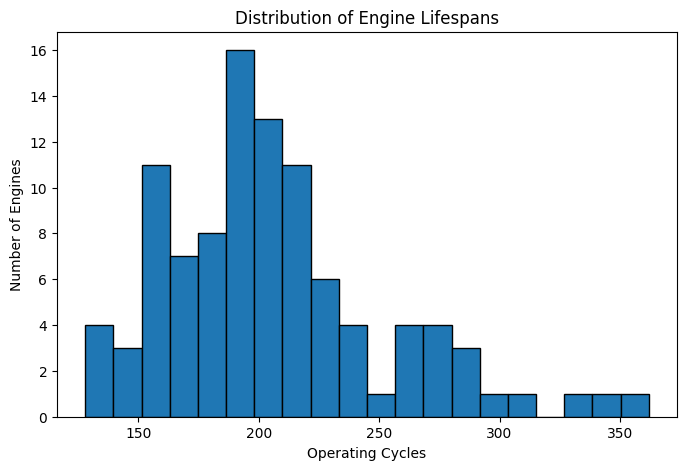

In [13]:
train_df.groupby('unit_number')['time_in_cycles'].max().plot(
    kind='hist',
    bins=20,
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Distribution of Engine Lifespans')
plt.xlabel('Operating Cycles')
plt.ylabel('Number of Engines')
plt.show()

In [14]:
train_df[train_df['unit_number'] == 1].shape

(192, 26)

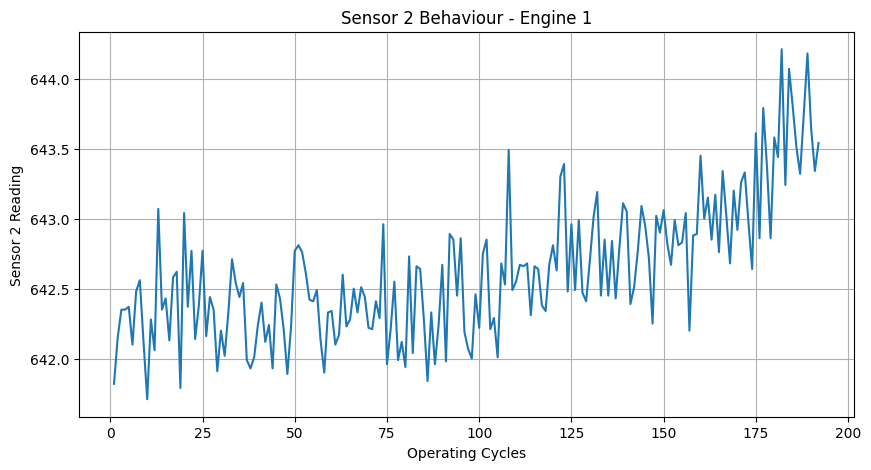

In [15]:
engine_1 = train_df[train_df['unit_number'] == 1]

plt.figure(figsize=(10, 5))
plt.plot(engine_1['time_in_cycles'], engine_1['sensor_2'])

plt.title('Sensor 2 Behaviour - Engine 1')
plt.xlabel('Operating Cycles')
plt.ylabel('Sensor 2 Reading')
plt.grid(True)

plt.show()

In [16]:
lifespans = train_df.groupby('unit_number')['time_in_cycles'].max()

lifespans.describe()

,time_in_cycles
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


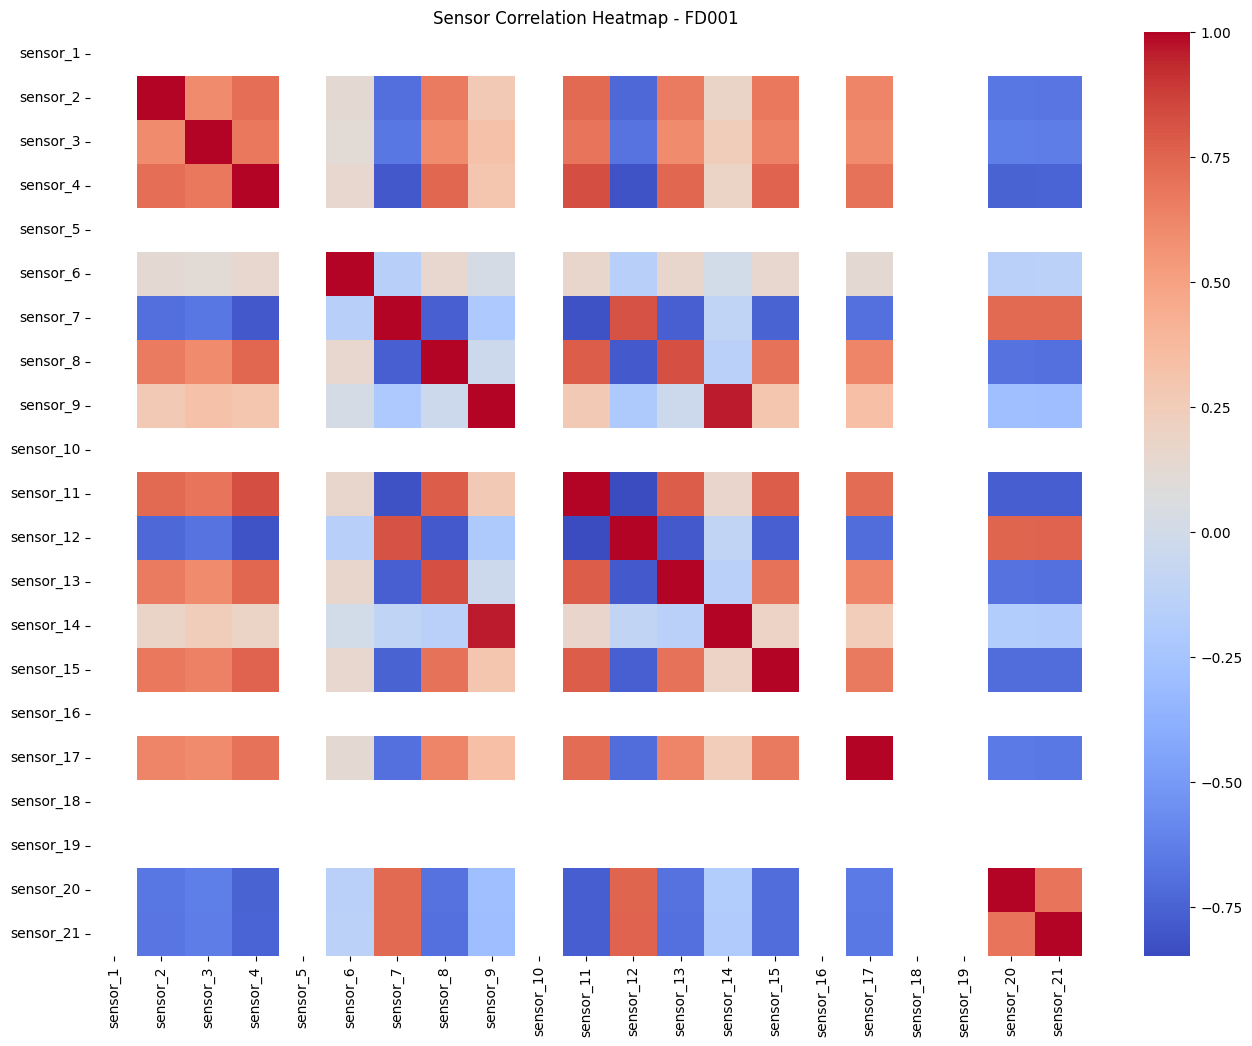

In [17]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    train_df.iloc[:, 5:].corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Sensor Correlation Heatmap - FD001')
plt.show()

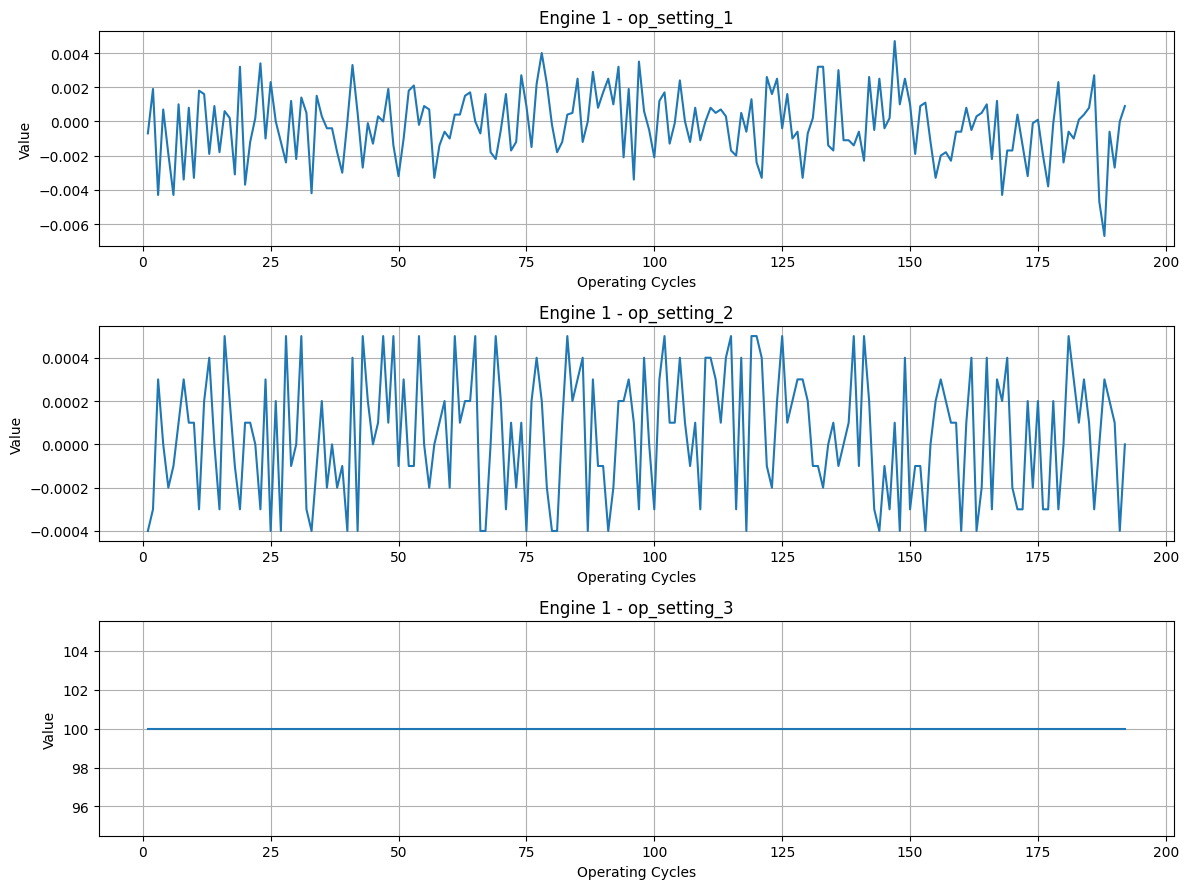

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

settings = ['op_setting_1', 'op_setting_2', 'op_setting_3']

for i, setting in enumerate(settings):
    axes[i].plot(engine_1['time_in_cycles'], engine_1[setting])
    axes[i].set_title(f'Engine 1 - {setting}')
    axes[i].set_xlabel('Operating Cycles')
    axes[i].set_ylabel('Value')
    axes[i].grid(True)

plt.tight_layout()
plt.show()

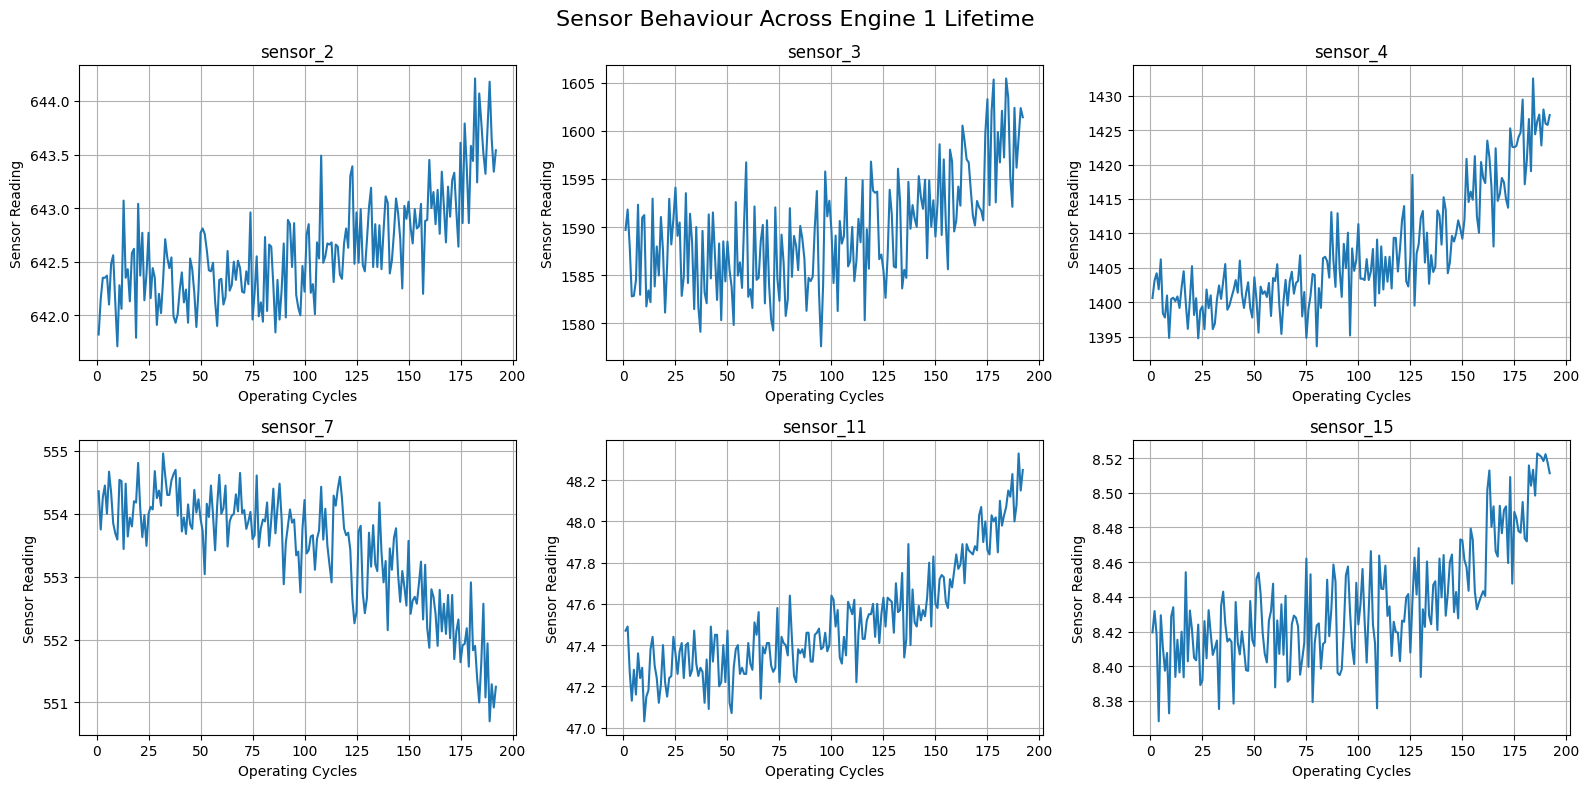

In [19]:
sensors = ['sensor_2', 'sensor_3', 'sensor_4',
            'sensor_7', 'sensor_11', 'sensor_15']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for sensor, ax in zip(sensors, axes.flatten()):
    ax.plot(engine_1['time_in_cycles'], engine_1[sensor])
    ax.set_title(sensor)
    ax.set_xlabel('Operating Cycles')
    ax.set_ylabel('Sensor Reading')
    ax.grid(True)

plt.suptitle('Sensor Behaviour Across Engine 1 Lifetime', fontsize=16)
plt.tight_layout()
plt.show()

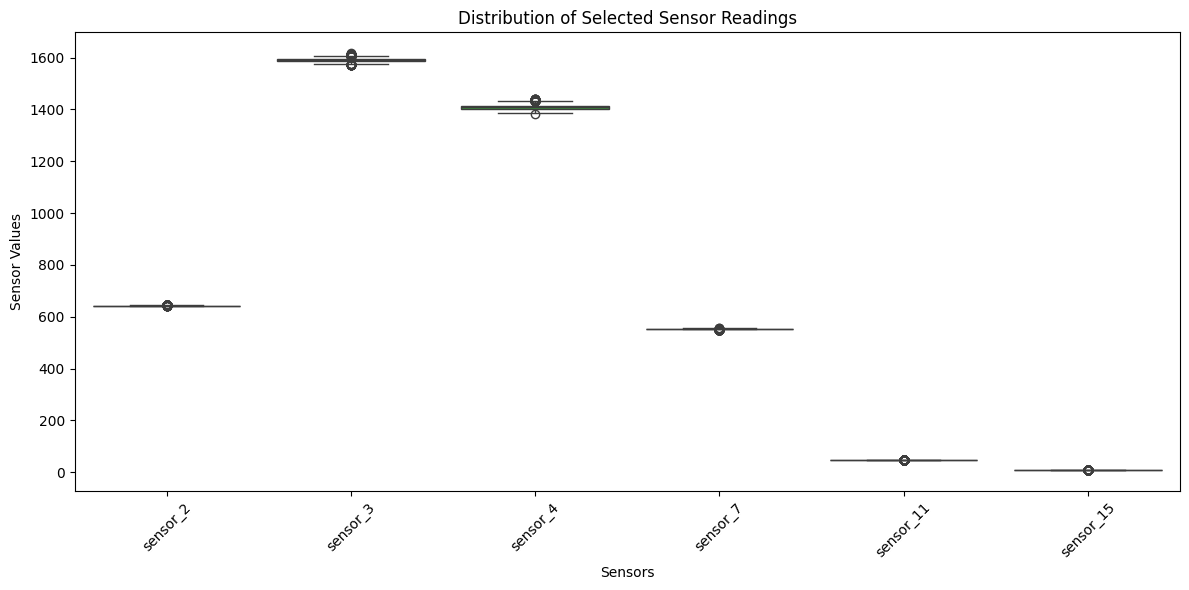

In [20]:
sensors = ['sensor_2', 'sensor_3', 'sensor_4',
            'sensor_7', 'sensor_11', 'sensor_15']

plt.figure(figsize=(12, 6))

sns.boxplot(data=train_df[sensors])

plt.title('Distribution of Selected Sensor Readings')
plt.xlabel('Sensors')
plt.ylabel('Sensor Values')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

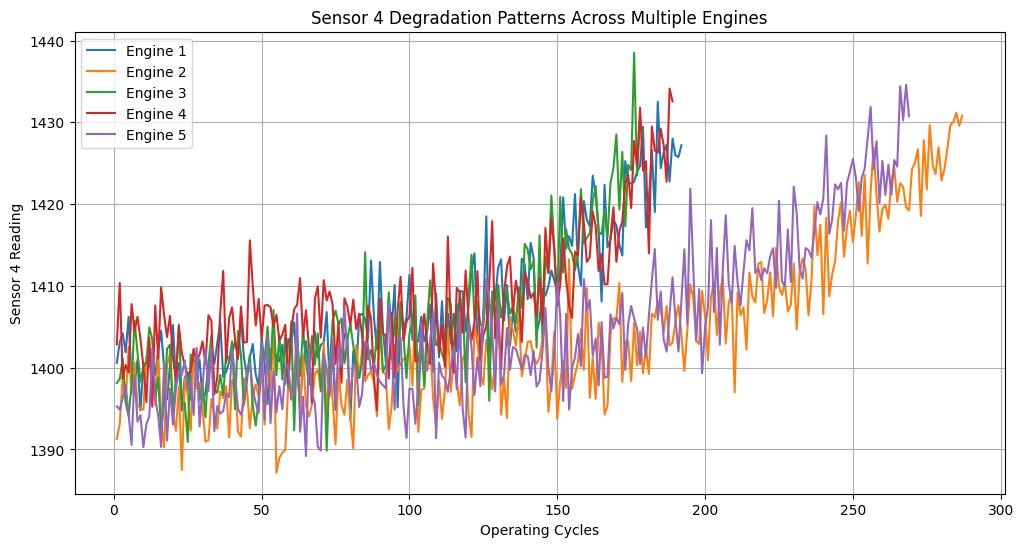

In [21]:
plt.figure(figsize=(12, 6))

for unit in range(1, 6):
    engine = train_df[train_df['unit_number'] == unit]
    plt.plot(engine['time_in_cycles'], engine['sensor_4'], label=f'Engine {unit}')

plt.title('Sensor 4 Degradation Patterns Across Multiple Engines')
plt.xlabel('Operating Cycles')
plt.ylabel('Sensor 4 Reading')
plt.legend()
plt.grid(True)

plt.show()

In [22]:
train_df['RUL'] = (
    train_df.groupby('unit_number')['time_in_cycles'].transform('max')
    - train_df['time_in_cycles']
)

train_df.head()

,unit_number,time_in_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


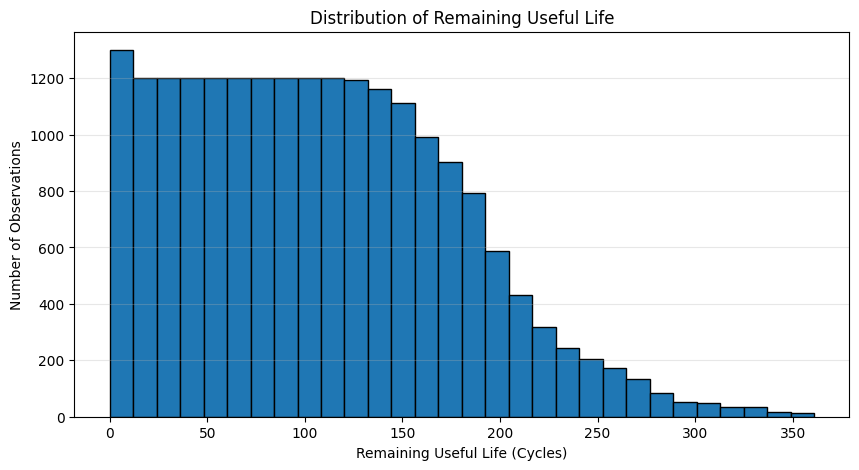

In [23]:
plt.figure(figsize=(10, 5))

plt.hist(train_df['RUL'], bins=30, edgecolor='black')

plt.title('Distribution of Remaining Useful Life')
plt.xlabel('Remaining Useful Life (Cycles)')
plt.ylabel('Number of Observations')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [24]:
RUL_CAP = 125

train_df['RUL_capped'] = np.minimum(train_df['RUL'], RUL_CAP)

train_df[['unit_number', 'time_in_cycles', 'RUL', 'RUL_capped']].head(10)

,unit_number,time_in_cycles,RUL,RUL_capped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


In [25]:
sensor_columns = [f'sensor_{i}' for i in range(1, 22)]

sensor_std = train_df[sensor_columns].std().sort_values()

sensor_std

,0
sensor_19,0.000000e+00
sensor_18,0.000000e+00
sensor_16,1.556432e-14
sensor_10,4.660829e-13
sensor_5,3.394700e-12
sensor_1,6.537152e-11
sensor_6,1.388985e-03
sensor_15,3.750504e-02
sensor_8,7.098548e-02
sensor_13,7.191892e-02


In [26]:
low_variance_sensors = sensor_std[sensor_std < 0.01]

print("Sensors with very low variation:")
print(low_variance_sensors)

print("\nNumber of sensors identified:", len(low_variance_sensors))

Sensors with very low variation:
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.556432e-14
sensor_10    4.660829e-13
sensor_5     3.394700e-12
sensor_1     6.537152e-11
sensor_6     1.388985e-03
dtype: float64

Number of sensors identified: 7


In [27]:
selected_sensors = [
    sensor for sensor in sensor_columns
    if sensor not in low_variance_sensors.index
]

print("Selected sensors:", selected_sensors)
print("\nTotal selected sensors:", len(selected_sensors))

Selected sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Total selected sensors: 14


In [28]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))

print("MinMaxScaler imported and initialized successfully!")

MinMaxScaler imported and initialized successfully!


In [29]:
from sklearn.model_selection import train_test_split

engine_ids = train_df['unit_number'].unique()

train_engines, val_engines = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))

Training engines: 80
Validation engines: 20


In [30]:
train_data = train_df[train_df['unit_number'].isin(train_engines)].copy()

val_data = train_df[train_df['unit_number'].isin(val_engines)].copy()

print("Training data shape:", train_data.shape)
print("Validation data shape:", val_data.shape)

Training data shape: (16561, 28)
Validation data shape: (4070, 28)


In [31]:
scaler.fit(train_data[selected_sensors])

print("Scaler fitted successfully!")
print("Number of features:", scaler.n_features_in_)

Scaler fitted successfully!
Number of features: 14


In [32]:
train_data[selected_sensors] = scaler.transform(
    train_data[selected_sensors]
)

val_data[selected_sensors] = scaler.transform(
    val_data[selected_sensors]
)

print("Training and validation sensor scaling completed!")

print("\nTraining sensor range:")
print(train_data[selected_sensors].min().min(),
      train_data[selected_sensors].max().max())

print("\nValidation sensor range:")
print(val_data[selected_sensors].min().min(),
      val_data[selected_sensors].max().max())

Training and validation sensor scaling completed!

Training sensor range:
0.0 1.0

Validation sensor range:
-0.05222024866785091 1.0059880239520957


In [33]:
SEQUENCE_LENGTH = 30

print("Sequence length:", SEQUENCE_LENGTH)
print("Each sequence will contain 30 operating cycles.")
print("Number of input features:", len(selected_sensors))

Sequence length: 30
Each sequence will contain 30 operating cycles.
Number of input features: 14


In [34]:
def create_sequences(data, sequence_length, feature_columns):
    X = []
    y = []

    for unit in data['unit_number'].unique():
        engine_data = data[data['unit_number'] == unit]

        engine_data = engine_data.sort_values('time_in_cycles')

        features = engine_data[feature_columns].values
        targets = engine_data['RUL_capped'].values

        for i in range(len(engine_data) - sequence_length + 1):
            X.append(features[i:i + sequence_length])
            y.append(targets[i + sequence_length - 1])

    return np.array(X), np.array(y)


print("Sequence generation function created successfully!")

Sequence generation function created successfully!


In [35]:
X_train, y_train = create_sequences(
    train_data, SEQUENCE_LENGTH, selected_sensors
)

X_val, y_val = create_sequences(
    val_data, SEQUENCE_LENGTH, selected_sensors
)

print("Training data shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("\nValidation data shape:", X_val.shape)
print("Validation target shape:", y_val.shape)

Training data shape: (14241, 30, 14)
Training target shape: (14241,)

Validation data shape: (3490, 30, 14)
Validation target shape: (3490,)


In [36]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices('GPU')

print("Available GPUs:", gpus)

TensorFlow version: 2.21.0
Available GPUs: []


In [37]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

print("LSTM components imported successfully!")

LSTM components imported successfully!


In [38]:
model = Sequential([
    Input(shape=(SEQUENCE_LENGTH, len(selected_sensors))),
    LSTM(64),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

print("LSTM architecture created successfully!")

LSTM architecture created successfully!


In [39]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,337 (87.25 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
)

print("Model compiled successfully!")

Model compiled successfully!


In [41]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("Early stopping configured successfully!")

Early stopping configured successfully!


In [42]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - loss: 3298.2036 - mean_absolute_error: 48.2046 - val_loss: 1744.4012 - val_mean_absolute_error: 37.0296
Epoch 2/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 1771.0338 - mean_absolute_error: 37.2800 - val_loss: 1746.9124 - val_mean_absolute_error: 36.9306
Epoch 3/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 1769.1022 - mean_absolute_error: 37.2887 - val_loss: 1706.7695 - val_mean_absolute_error: 36.7155
Epoch 4/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 1124.3890 - mean_absolute_error: 28.5102 - val_loss: 281.2339 - val_mean_absolute_error: 13.2181
Epoch 5/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 303.7357 - mean_absolute_error: 13.4401 - val_loss: 167.4865 - val_mean_absolute_error: 9.5302
Epoch 6/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - loss: 251.8924 - mean_absolute_error: 11.9704 - val_loss: 166.7368 - val_mean_absolute_error: 9.5713
Epoch 7/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step

In [43]:
best_epoch = np.argmin(history.history['val_loss']) + 1

best_val_loss = min(history.history['val_loss'])
best_val_mae = history.history['val_mean_absolute_error'][best_epoch - 1]

print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)
print("Best Validation MAE:", best_val_mae)

Best Epoch: 17
Best Validation Loss: 138.1444854736328
Best Validation MAE: 8.698294639587402


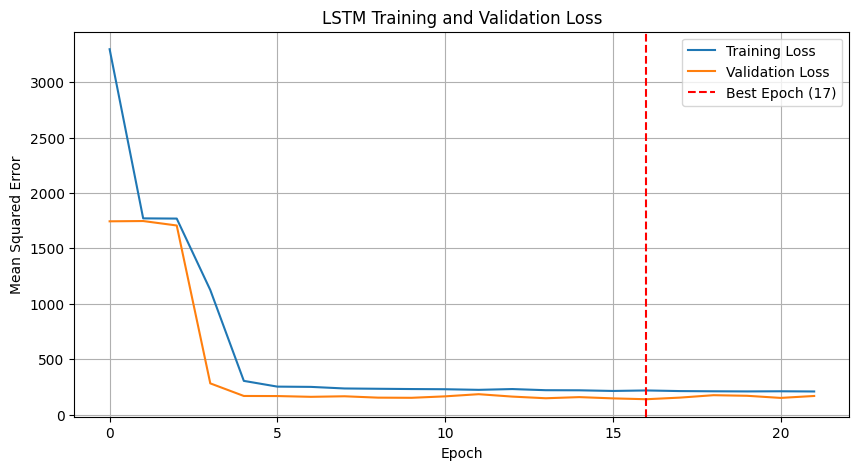

In [44]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.axvline(
    x=best_epoch - 1,
    color='red',
    linestyle='--',
    label=f'Best Epoch ({best_epoch})'
)

plt.title('LSTM Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.show()

In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_val).flatten()

mae = mean_absolute_error(y_val, y_pred)
mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_val, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step
Model Evaluation Results
------------------------
MAE: 8.698294639587402
MSE: 138.1444854736328
RMSE: 11.753488225783562
R2 Score: 0.9207600951194763


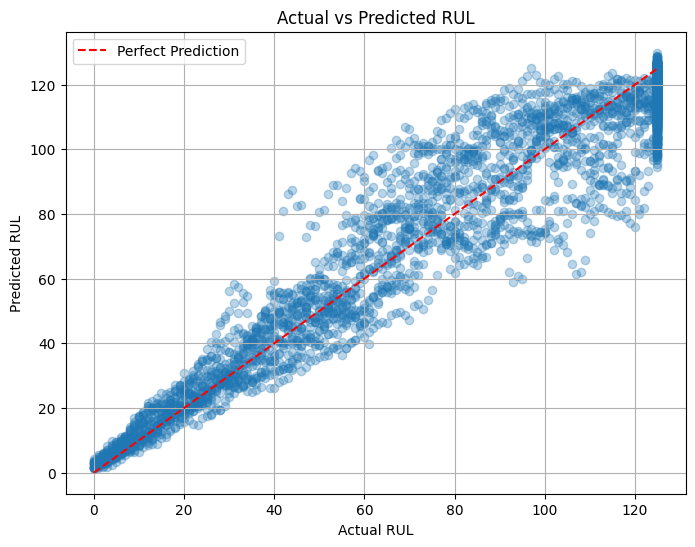

In [46]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred, alpha=0.3)

plt.plot(
    [0, 125],
    [0, 125],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.title('Actual vs Predicted RUL')
plt.legend()
plt.grid(True)
plt.show()

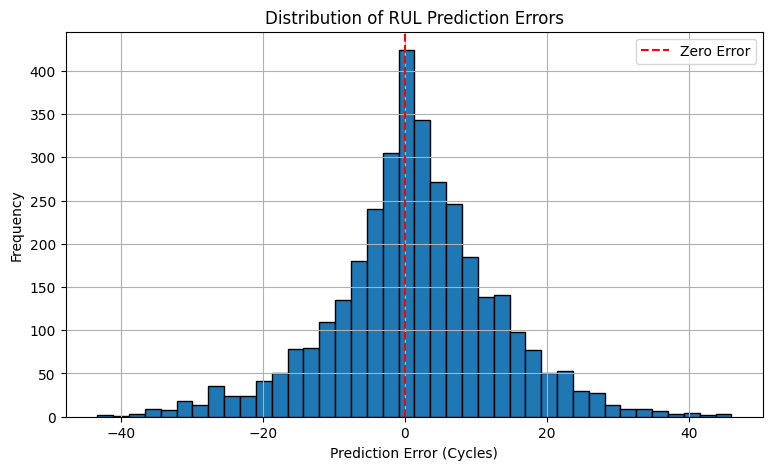

In [47]:
prediction_errors = y_val - y_pred

plt.figure(figsize=(9, 5))

plt.hist(prediction_errors, bins=40, edgecolor='black')

plt.axvline(
    x=0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

plt.title('Distribution of RUL Prediction Errors')
plt.xlabel('Prediction Error (Cycles)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()

In [48]:
test_df = pd.read_csv(
    '/content/cmapss_data/test_FD001.txt',
    sep=r'\s+',
    header=None,
    names=columns
)

actual_rul = pd.read_csv(
    '/content/cmapss_data/RUL_FD001.txt',
    sep=r'\s+',
    header=None,
    names=['RUL']
)

print("Test Dataset Shape:", test_df.shape)
print("Actual RUL Shape:", actual_rul.shape)

print("\nFirst 5 rows of Test Dataset:")
display(test_df.head())

print("\nFirst 5 Actual RUL Values:")
display(actual_rul.head())

Test Dataset Shape: (13096, 26)
Actual RUL Shape: (100, 1)

First 5 rows of Test Dataset:


,unit_number,time_in_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130



First 5 Actual RUL Values:


,RUL
0,112
1,98
2,69
3,82
4,91


In [49]:
test_data = test_df.copy()

test_data[selected_sensors] = scaler.transform(
    test_data[selected_sensors]
)

print("Test data scaling completed!")

print("Scaled test data shape:", test_data.shape)

print("\nScaled sensor value range:")
print("Minimum:", test_data[selected_sensors].min().min())
print("Maximum:", test_data[selected_sensors].max().max())

Test data scaling completed!
Scaled test data shape: (13096, 26)

Scaled sensor value range:
Minimum: -0.04360148245039852
Maximum: 1.081023454157787


In [50]:
X_test = []

for unit in test_data['unit_number'].unique():

    engine_data = test_data[
        test_data['unit_number'] == unit
    ].sort_values('time_in_cycles')

    features = engine_data[selected_sensors].values

    last_sequence = features[-SEQUENCE_LENGTH:]

    X_test.append(last_sequence)

X_test = np.array(X_test)

print("Test sequences created successfully!")
print("X_test shape:", X_test.shape)

Test sequences created successfully!
X_test shape: (100, 30, 14)


In [51]:
y_test_pred = model.predict(X_test).flatten()

print("RUL predictions completed!")
print("Number of predictions:", len(y_test_pred))

print("\nFirst 10 predicted RUL values:")
print(y_test_pred[:10])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
RUL predictions completed!
Number of predictions: 100

First 10 predicted RUL values:
[109.72063  117.44497   48.578724  82.676056 103.502716 107.34622
 108.903625  96.62509  118.03534   81.80818 ]


In [52]:
test_mae = mean_absolute_error(actual_rul['RUL'], y_test_pred)
test_mse = mean_squared_error(actual_rul['RUL'], y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(actual_rul['RUL'], y_test_pred)

print("FINAL TEST EVALUATION")
print("---------------------")
print("MAE:", test_mae)
print("MSE:", test_mse)
print("RMSE:", test_rmse)
print("R2 Score:", test_r2)

FINAL TEST EVALUATION
---------------------
MAE: 10.572705268859863
MSE: 202.48841857910156
RMSE: 14.22984253528835
R2 Score: 0.8827425241470337


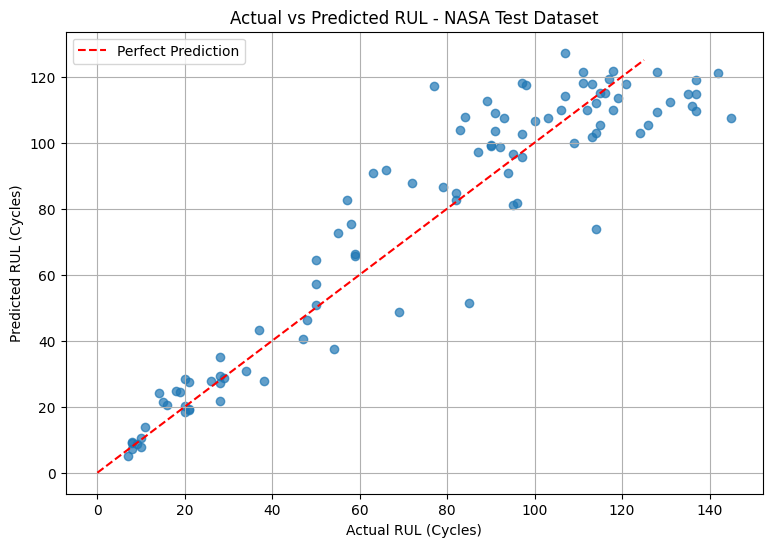

In [53]:
plt.figure(figsize=(9, 6))

plt.scatter(
    actual_rul['RUL'],
    y_test_pred,
    alpha=0.7
)

plt.plot(
    [0, 125],
    [0, 125],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual RUL (Cycles)')
plt.ylabel('Predicted RUL (Cycles)')
plt.title('Actual vs Predicted RUL - NASA Test Dataset')

plt.legend()
plt.grid(True)
plt.show()

In [54]:
import joblib
import os

os.makedirs('/content/rul_project', exist_ok=True)

# Save trained LSTM model
model.save('/content/rul_project/rul_lstm_model.keras')

# Save preprocessing components
preprocessing_objects = {
    'scaler': scaler,
    'selected_sensors': selected_sensors,
    'sequence_length': SEQUENCE_LENGTH,
    'rul_cap': RUL_CAP
}

joblib.dump(
    preprocessing_objects,
    '/content/rul_project/rul_preprocessing.pkl'
)

print("Model and preprocessing files saved successfully!")

print("\nSaved files:")
print(os.listdir('/content/rul_project'))

Model and preprocessing files saved successfully!

Saved files:
['rul_preprocessing.pkl', 'rul_lstm_model.keras']


In [55]:
import shutil
from google.colab import files

shutil.make_archive(
    '/content/RUL_Project_Files',
    'zip',
    '/content/rul_project'
)

files.download('/content/RUL_Project_Files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
import tensorflow as tf
import sklearn
import numpy as np

print("TensorFlow:", tf.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Scikit-learn: 1.6.1
NumPy: 2.4.6


In [57]:
import os

os.listdir('/content/cmapss_data')

['readme.txt',
 'test_FD003.txt',
 'test_FD001.txt',
 'train_FD002.txt',
 'train_FD001.txt',
 'test_FD004.txt',
 'train_FD003.txt',
 'RUL_FD003.txt',
 'train_FD004.txt',
 'Damage Propagation Modeling.pdf',
 'RUL_FD002.txt',
 'test_FD002.txt',
 'RUL_FD001.txt',
 '6. Turbofan Engine Degradation Simulation Data Set',
 'RUL_FD004.txt']

In [58]:
# Select Engine 1 from the NASA test dataset
engine_data = test_df[test_df['unit_number'] == 1].copy()

# Sort readings by engine cycle
engine_data = engine_data.sort_values('time_in_cycles')

# Extract the last 30 cycles and selected sensors
sample_data = engine_data[selected_sensors].tail(30)

# Check the extracted data
print("Dataset shape:", sample_data.shape)

# Save as CSV
sample_data.to_csv('/content/engine_1_sensor_data.csv', index=False)

print("CSV file created successfully!")

Dataset shape: (30, 14)
CSV file created successfully!


In [59]:
from google.colab import files

files.download('/content/engine_1_sensor_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>